# 3. Modelagem: classificação de detratores

Este notebook constrói um modelo que prevê se o cliente será **detrator** (NPS de 0 a 6) usando apenas variáveis operacionais disponíveis **antes** da pesquisa de NPS.

**Uso de negócio:** ordenar os pedidos por risco de detração, para que o time de atendimento possa agir de forma proativa (acompanhar a entrega, pedir desculpas, oferecer compensação) antes que a experiência vire uma nota ruim. É a resposta direta à pergunta central do projeto, formulada na fase exploratória.

**Roteiro**

1. Carga e definição da variável alvo
2. Seleção de variáveis e controle de vazamento de dados
3. Divisão entre treino e teste
4. Baseline: o classificador trivial
5. Pré-processamento
6. Treinamento da Regressão Logística
7. Avaliação: matriz de confusão e métricas por classe
8. Interpretação dos coeficientes
9. Probabilidades e ROC-AUC
10. Comparação entre algoritmos
11. Escolha do limiar de decisão
12. Modelo final e exportação
13. Conclusões e limitações

### Importação e configuração

Além das bibliotecas já usadas nos notebooks anteriores, entram aqui o scikit-learn (modelagem) e o joblib (para salvar o modelo treinado).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Mesmo padrão visual dos notebooks anteriores
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

## 1. Carga e definição da variável alvo

O alvo é **binário**: 1 para detrator e 0 para não detrator (neutro ou promotor).

Por que não manter as três categorias do NPS? Porque neutro tem 281 casos e promotor apenas 110. Com tão poucos exemplos, um modelo de três classes erra demais nas duas menores. Além disso, a pergunta de negócio é binária: quem corre risco de virar detrator?

In [2]:
df = pd.read_csv('../data/processed/nps_tratado.csv')

df["isdetrator"] = (df['nps_category'] == 'Detrator').astype(int)

print(df["isdetrator"].value_counts())
print(f"Proporção de detratores: {df['isdetrator'].mean():.1%}")

isdetrator
1    2109
0     391
Name: count, dtype: int64
Proporção de detratores: 84.4%


## 2. Seleção de variáveis e controle de vazamento de dados

**Vazamento de dados** acontece quando o modelo aprende com uma informação que não estará disponível no momento real de uso. O modelo fica excelente no notebook e falha em produção.

Como a previsão acontece **antes** da pesquisa de NPS, toda variável que só existe depois (ou junto) da resposta do cliente fica de fora:

| Coluna | Decisão | Motivo |
|---|---|---|
| `nps_score`, `nps_category` | Fora | São a variável alvo |
| `repeat_purchase_30d` | Fora | Acontece nos 30 dias **após** a avaliação |
| `csat_internal_score` | Fora | É uma pesquisa de satisfação, provavelmente respondida junto com o NPS. O impacto dessa exclusão é medido na seção 10 |
| `customer_id`, `order_id` | Fora | Identificadores, sem significado preditivo |
| `complaints_count`, `customer_service_contacts`, `resolution_time_days` | Dentro | **Premissa declarada:** ocorrem durante o ciclo do pedido, antes da coleta do NPS. A base não tem datas, então essa premissa não pode ser verificada |
| Demais variáveis de cliente, pedido e entrega | Dentro | Conhecidas no momento da entrega |

Variáveis com correlação baixa na análise exploratória, como `delivery_time_days` e as de perfil do cliente, foram **mantidas de propósito**. Correlação mede apenas relação linear entre duas variáveis isoladas, e cabe ao modelo decidir o peso de cada uma. No caso de `delivery_time_days` existe um motivo extra: manter a variável permite confirmar, por outra técnica, o achado central da análise exploratória.

In [3]:
NUM_FEATURES = [
    "customer_age", "customer_tenure_months",
    "order_value", "items_quantity", "discount_value", "payment_installments",
    "delivery_time_days", "delivery_delay_days", "freight_value", "delivery_attempts",
    "customer_service_contacts", "resolution_time_days", "complaints_count",
]
CAT_FEATURES = ["customer_region"]
FEATURES = NUM_FEATURES + CAT_FEATURES

X = df[FEATURES]
y = df["isdetrator"]

print(X.shape)
print(y.shape)

(2500, 14)
(2500,)


## 3. Divisão entre treino e teste

O modelo aprende com 80% das linhas e é avaliado nos 20% restantes, que ele nunca viu. Medir desempenho nos mesmos dados do treino avaliaria a capacidade de decorar, e não a de prever.

A divisão é **estratificada** (`stratify=y`) para manter a proporção de 84% de detratores nos dois conjuntos, o que é indispensável numa base desbalanceada. O `random_state=42` fixa o sorteio e garante que qualquer pessoa que rode este notebook obtenha exatamente os mesmos números.

O conjunto de teste é usado **uma única vez**, na seção 7. Todas as escolhas de modelo e de limiar são feitas por validação cruzada dentro do treino.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Treino: {X_train.shape[0]} linhas | detratores: {y_train.mean():.1%}")
print(f"Teste:  {X_test.shape[0]} linhas | detratores: {y_test.mean():.1%}")

Treino: 2000 linhas | detratores: 84.4%
Teste:  500 linhas | detratores: 84.4%


## 4. Baseline: o classificador trivial

Antes de qualquer modelo, a pergunta é: quanto acerta quem responde "detrator" para todo mundo?

**Por isso a acurácia não serve como métrica aqui.** Com 84% de detratores na base, o chute trivial já tem 84% de acurácia sem aprender absolutamente nada.

As métricas usadas neste notebook são:

- **ROC-AUC:** a probabilidade de o modelo dar um risco maior a um detrator do que a um não detrator, sorteados ao acaso. Mede a capacidade de **ordenar** por risco, que é exatamente o uso de negócio, e não depende do limiar escolhido. 0,5 equivale a jogar uma moeda
- **Acurácia balanceada:** a média do acerto dentro de cada classe. O chute trivial tira 0,50
- **F1 macro:** a média do F1 das duas classes, dando o mesmo peso à classe minoritária

In [5]:
baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)
previsoes_baseline = baseline.predict(X_test)

print(f"Acurácia: {accuracy_score(y_test, previsoes_baseline):.4f}   <- alta, e ainda assim inútil")
print(f"Acurácia Balanceada: {balanced_accuracy_score(y_test, previsoes_baseline):.4f}")
print(f"F1 Macro: {f1_score(y_test, previsoes_baseline, average='macro'):.4f}")

Acurácia: 0.8440   <- alta, e ainda assim inútil
Acurácia Balanceada: 0.5000
F1 Macro: 0.4577


## 5. Pré-processamento

Duas transformações são necessárias antes de treinar um modelo linear:

- **`StandardScaler` nas variáveis numéricas.** As escalas são muito diferentes (`order_value` chega a 1.983 e `delivery_delay_days` vai até 8). A padronização coloca todas com média 0 e desvio 1, o que evita que a grandeza dos números influencie o peso das variáveis e torna os coeficientes comparáveis entre si na seção 8
- **`OneHotEncoder` na região.** O modelo não processa texto. Cada região vira uma coluna de 0 e 1, e o `drop='first'` remove uma delas, que passa a ser a categoria de referência. Sem isso, as colunas ficam perfeitamente redundantes entre si, o que prejudica modelos lineares

O `ColumnTransformer` aplica cada transformação ao seu grupo de colunas. Das 14 variáveis de entrada saem 17 colunas: 13 numéricas e 4 de região (5 categorias menos a de referência).

In [6]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(drop='first'), CAT_FEATURES),
])

X_train_prep = preprocess.fit_transform(X_train)
print(X_train_prep.shape)
print(preprocess.get_feature_names_out())

(2000, 17)
['num__customer_age' 'num__customer_tenure_months' 'num__order_value'
 'num__items_quantity' 'num__discount_value' 'num__payment_installments'
 'num__delivery_time_days' 'num__delivery_delay_days' 'num__freight_value'
 'num__delivery_attempts' 'num__customer_service_contacts'
 'num__resolution_time_days' 'num__complaints_count'
 'cat__customer_region_Nordeste' 'cat__customer_region_Norte'
 'cat__customer_region_Sudeste' 'cat__customer_region_Sul']


## 6. Treinamento da Regressão Logística

A Regressão Logística atribui um peso a cada variável, soma tudo e passa o resultado por uma função que o comprime no intervalo de 0 a 1, gerando uma probabilidade.

Dois detalhes importantes:

- **`Pipeline`** encadeia o pré-processamento e o modelo num objeto só. Além da conveniência, isso evita um vazamento sutil: as médias e desvios do `StandardScaler` passam a ser aprendidos somente com os dados de treino de cada etapa, inclusive dentro de cada divisão da validação cruzada
- **`class_weight='balanced'`** faz os erros na classe minoritária pesarem mais, proporcionalmente à raridade dela. Sem isso, o caminho mais fácil para o modelo seria se aproximar do chute trivial

In [7]:
pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight='balanced'))
])

pipe.fit(X_train, y_train)
previsoes = pipe.predict(X_test)

print(f"Acurácia: {accuracy_score(y_test, previsoes):.4f}")
print(f"Acurácia Balanceada: {balanced_accuracy_score(y_test, previsoes):.4f}")
print(f"F1 Macro: {f1_score(y_test, previsoes, average='macro'):.4f}")

Acurácia: 0.8040
Acurácia Balanceada: 0.7585
F1 Macro: 0.7004


**A acurácia caiu em relação ao baseline (0,804 contra 0,844) e, ainda assim, o modelo é muito melhor.** A acurácia balanceada subiu de 0,500 para 0,759.

O baseline acerta 100% dos detratores e 0% dos não detratores. O modelo troca alguns acertos fáceis de detrator por algo que o baseline não consegue fazer: identificar o cliente satisfeito. Na prática, um modelo que marca todos como detratores não permite priorizar ninguém, que é justamente o que o negócio precisa.

## 7. Avaliação: matriz de confusão e métricas por classe

As métricas médias escondem o detalhe. A matriz de confusão mostra o que aconteceu com cada uma das 500 linhas do conjunto de teste, e os dois tipos de erro têm custos bem diferentes:

- **Alarme falso** (não detrator classificado como detrator): o time entra em contato com um cliente que avaliaria bem. O custo é baixo e o contato pode até ser positivo
- **Detrator não identificado**: um cliente insatisfeito que ninguém percebeu. Esse é o erro caro, e é ele que orienta a escolha do limiar na seção 11

In [8]:
print(confusion_matrix(y_test, previsoes))
print(classification_report(y_test, previsoes, target_names=["Não detrator", "Detrator"]))

[[ 54  24]
 [ 74 348]]
              precision    recall  f1-score   support

Não detrator       0.42      0.69      0.52        78
    Detrator       0.94      0.82      0.88       422

    accuracy                           0.80       500
   macro avg       0.68      0.76      0.70       500
weighted avg       0.86      0.80      0.82       500



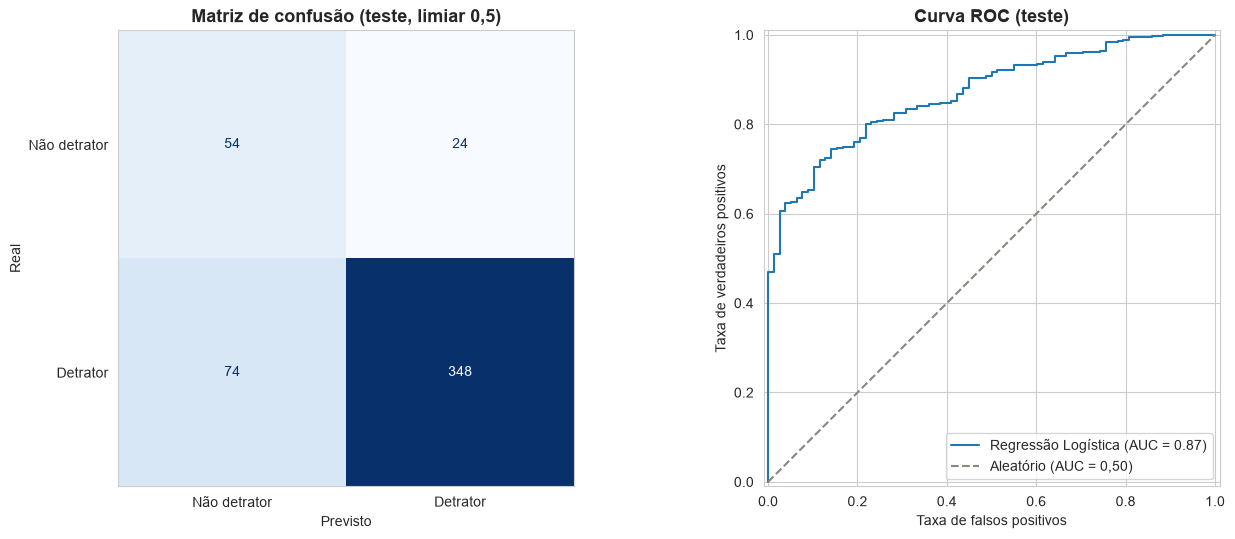

In [9]:
proba = pipe.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, previsoes, display_labels=["Não detrator", "Detrator"],
    cmap='Blues', colorbar=False, ax=axes[0],
)
axes[0].set_title('Matriz de confusão (teste, limiar 0,5)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Previsto')
axes[0].set_ylabel('Real')
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, proba, name='Regressão Logística', ax=axes[1])
axes[1].plot([0, 1], [0, 1], '--', color='#888780', label='Aleatório (AUC = 0,50)')
axes[1].set_title('Curva ROC (teste)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Taxa de falsos positivos')
axes[1].set_ylabel('Taxa de verdadeiros positivos')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('../reports/figures/14_matriz_confusao_roc.png', dpi=120, bbox_inches='tight')
plt.show()

**Leitura da matriz.** Dos 422 detratores do conjunto de teste, o modelo identifica 348 (recall de 82%) e deixa passar 74. Dos 78 não detratores, reconhece 54 e sinaliza 24 por engano. O baseline, em comparação, não reconhecia nenhum não detrator.

**Precisão de 94% na classe detrator.** Quando o modelo aponta um cliente como detrator, ele acerta em 94% das vezes. Se o time contatar os 372 clientes sinalizados, 348 eram realmente insatisfeitos: quase nenhum esforço desperdiçado.

**Precisão de 42% na classe não detrator.** Afirmar que alguém está satisfeito é difícil num universo em que 84% detratam. O sinal verde do modelo é bem menos confiável que o sinal vermelho, e isso precisa ser dito a quem for usar o resultado.

## 8. Interpretação dos coeficientes

Como as variáveis numéricas foram padronizadas, os coeficientes são comparáveis entre si. Coeficiente positivo aumenta a chance de detração, negativo reduz, e o valor absoluto indica o peso. Cada coeficiente responde: se essa variável subir um desvio padrão, quanto a chance de detração se move, mantendo as demais constantes.

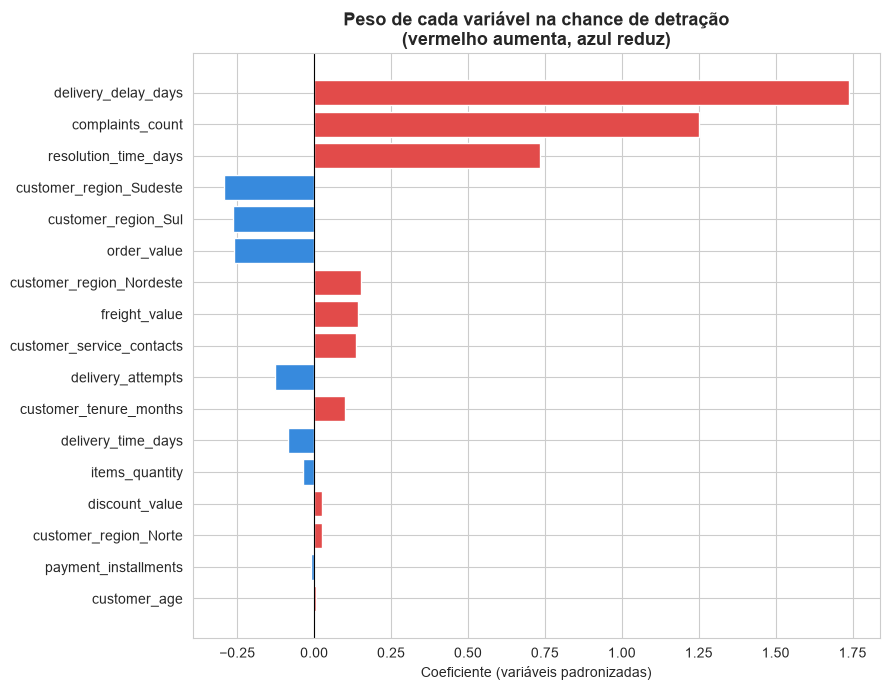

delivery_delay_days          1.738
complaints_count             1.251
resolution_time_days         0.733
customer_region_Nordeste     0.152
freight_value                0.141
customer_service_contacts    0.135
customer_tenure_months       0.101
discount_value               0.026
customer_region_Norte        0.026
customer_age                 0.006
payment_installments        -0.011
items_quantity              -0.036
delivery_time_days          -0.085
delivery_attempts           -0.128
order_value                 -0.262
customer_region_Sul         -0.264
customer_region_Sudeste     -0.293
dtype: float64

In [10]:
coeficientes = pd.Series(
    pipe.named_steps["model"].coef_[0],
    index=pipe.named_steps["preprocess"].get_feature_names_out(),
)
coeficientes.index = coeficientes.index.str.replace('num__', '').str.replace('cat__', '')
coeficientes = coeficientes.reindex(coeficientes.abs().sort_values().index)

cores = ['#E24B4A' if c > 0 else '#378ADD' for c in coeficientes]

plt.figure(figsize=(9, 7))
plt.barh(coeficientes.index, coeficientes.values, color=cores, edgecolor='white')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Peso de cada variável na chance de detração\n(vermelho aumenta, azul reduz)',
          fontsize=13, fontweight='bold')
plt.xlabel('Coeficiente (variáveis padronizadas)')
plt.tight_layout()
plt.savefig('../reports/figures/15_coeficientes_modelo.png', dpi=120, bbox_inches='tight')
plt.show()

coeficientes.sort_values(ascending=False).round(3)

**O modelo confirma o achado central da análise exploratória.** As duas variáveis sobre a mesma entrega terminam em extremos opostos: `delivery_delay_days` é de longe a mais forte (+1,74) e `delivery_time_days` é indistinguível de zero (-0,08). Duas técnicas diferentes, com lógicas diferentes, chegam à mesma conclusão: o cliente não reage a esperar, reage à promessa quebrada.

Na sequência aparecem `complaints_count` (+1,25) e `resolution_time_days` (+0,73). Já as variáveis de perfil do cliente e as características do pedido ficam todas abaixo de 0,3 em valor absoluto, coerente com o que a análise exploratória havia mostrado.

**Uma ressalva importante sobre `customer_service_contacts`.** Ela aparece com peso baixo (+0,14) apesar de ter correlação relevante com o NPS. O motivo é a **multicolinearidade**: contatos e reclamações têm correlação de 0,75 entre si, ou seja, carregam quase a mesma informação. O modelo concentra o peso em uma e praticamente zera a outra. Isso não significa que contatos não importem, e sim que, sabendo o número de reclamações, saber o número de contatos acrescenta pouco. Em modelos com variáveis correlacionadas, o coeficiente individual não deve ser lido como um ranking definitivo de importância.

**Coeficiente não é causalidade.** O modelo identifica associação. Dizer que reduzir o atraso diminui a detração é uma hipótese plausível, mas apenas um teste controlado comprovaria o mecanismo.

## 9. Probabilidades e ROC-AUC

O `.predict()` devolve um rótulo já decidido, mas o modelo calcula uma probabilidade, e ela é mais útil por dois motivos: permite **ordenar** os clientes por risco, que é o que o time de atendimento precisa, e permite avaliar o modelo sem depender do limiar escolhido.

In [11]:
roc_auc = roc_auc_score(y_test, proba)

print(f"ROC AUC: {roc_auc:.4f}")
print(f"Primeiras probabilidades: {proba[:5].round(3)}")
print(f"Valores reais:            {y_test.values[:5]}")

ROC AUC: 0.8701
Primeiras probabilidades: [0.471 0.962 0.974 0.924 0.347]
Valores reais:            [0 1 1 1 1]


ROC-AUC de 0,870 contra 0,500 do baseline: sorteando um detrator e um não detrator, em 87% das vezes o modelo atribui risco maior ao detrator.

## 10. Comparação entre algoritmos

Três famílias diferentes de algoritmo foram testadas com validação cruzada de 5 divisões, sempre **dentro do conjunto de treino**:

- **Regressão Logística**: modelo linear, simples e interpretável
- **Random Forest**: várias árvores em paralelo, captura não linearidades e interações
- **HistGradientBoosting**: árvores em sequência, cada uma corrigindo o erro da anterior

A validação cruzada divide o treino em 5 partes, treina em 4 e avalia na que sobrou, repetindo 5 vezes. Isso dá uma estimativa mais estável do que uma única divisão, e ainda permite medir a **variação** entre as partes.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "Baseline": DummyClassifier(strategy='most_frequent'),
    "Regressão Logística": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight='balanced', random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
}

linhas = []

for nome, modelo in modelos.items():
    pipe_teste = Pipeline([
        ("preprocess", preprocess),
        ("model", modelo)
    ])
    scores = cross_validate(pipe_teste, X_train, y_train, cv=cv,
                            scoring=["accuracy", "balanced_accuracy", "roc_auc", "f1_macro"],
                            n_jobs=-1)
    linhas.append({
        "modelo": nome,
        "Acurácia": scores["test_accuracy"].mean(),
        "Acurácia Balanceada": scores["test_balanced_accuracy"].mean(),
        "ROC AUC": scores["test_roc_auc"].mean(),
        "ROC AUC (desvio)": scores["test_roc_auc"].std(),
        "F1 Macro": scores["test_f1_macro"].mean(),
    })

pd.DataFrame(linhas).set_index("modelo").round(3)

,Acurácia,Acurácia Balanceada,ROC AUC,ROC AUC (desvio),F1 Macro
modelo,,,,,
Baseline,0.844,0.500,0.500,0.000,0.458
Regressão Logística,0.814,0.817,0.895,0.010,0.731
Random Forest,0.835,0.779,0.883,0.022,0.734
HistGradientBoosting,0.854,0.719,0.870,0.025,0.719


**O ranking por acurácia é quase o inverso do ranking por acurácia balanceada.** O HistGradientBoosting tem a maior acurácia (0,854) e a pior acurácia balanceada entre os modelos de verdade (0,719), ou seja, é o que mais se aproxima da estratégia do chute. Escolher pela acurácia levaria ao pior modelo para o negócio.

**Modelo escolhido: Regressão Logística.** Tem o melhor ROC-AUC (0,895) e a melhor acurácia balanceada (0,817), com o menor desvio entre as divisões (0,010 contra 0,022 e 0,025 das árvores), ou seja, é também o mais estável. O Random Forest leva o F1 macro por 3 milésimos, diferença irrelevante diante da vantagem nas duas métricas principais.

Como os modelos mais complexos não trouxeram ganho, fica o mais simples, que ainda tem a vantagem de ser diretamente interpretável.

In [13]:
# Qual seria o impacto de incluir o csat_internal_score, excluído por risco de vazamento?
num_com_csat = NUM_FEATURES + ["csat_internal_score"]

pipe_csat = Pipeline([
    ("preprocess", ColumnTransformer([
        ("num", StandardScaler(), num_com_csat),
        ("cat", OneHotEncoder(drop='first'), CAT_FEATURES),
    ])),
    ("model", LogisticRegression(max_iter=1000, class_weight='balanced'))
])

X_train_csat = df.loc[X_train.index, num_com_csat + CAT_FEATURES]

comparacao = {}
for nome, modelo_teste, dados in [("Sem CSAT", pipe, X_train), ("Com CSAT", pipe_csat, X_train_csat)]:
    s = cross_validate(modelo_teste, dados, y_train, cv=cv,
                       scoring=["roc_auc", "balanced_accuracy", "f1_macro"])
    comparacao[nome] = {
        "ROC AUC": s["test_roc_auc"].mean(),
        "Acurácia Balanceada": s["test_balanced_accuracy"].mean(),
        "F1 Macro": s["test_f1_macro"].mean(),
    }

pd.DataFrame(comparacao).T.round(3)

,ROC AUC,Acurácia Balanceada,F1 Macro
Sem CSAT,0.895,0.817,0.731
Com CSAT,0.896,0.814,0.727


Incluir o `csat_internal_score` não melhora o modelo (ROC-AUC de 0,896 contra 0,895). O resultado é coerente com a análise exploratória, que mostrou o CSAT fortemente ligado ao tempo de resolução (correlação de -0,74), informação que o modelo já possui através de `resolution_time_days`. A exclusão elimina o risco de vazamento sem nenhum custo de desempenho.

## 11. Escolha do limiar de decisão

Por padrão o modelo classifica como detrator quem tem probabilidade acima de 0,5, mas esse corte é uma **decisão de negócio**, não estatística.

Para escolher o limiar sem contaminar o conjunto de teste, as probabilidades vêm de validação cruzada dentro do treino: cada linha recebe a previsão de um modelo que não a viu durante o treinamento.

In [14]:
proba_cv = cross_val_predict(pipe, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

limiares = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
resultado_limiar = []

for limiar in limiares:
    previsao = (proba_cv >= limiar).astype(int)
    resultado_limiar.append({
        "limiar": limiar,
        "recall": recall_score(y_train, previsao),
        "precisao": precision_score(y_train, previsao),
        "acuracia_balanceada": balanced_accuracy_score(y_train, previsao),
    })

tabela_limiar = pd.DataFrame(resultado_limiar)
print(tabela_limiar.round(3).to_string(index=False))

 limiar  recall  precisao  acuracia_balanceada
    0.2   0.936     0.914                0.732
    0.3   0.900     0.935                0.782
    0.4   0.859     0.946                0.798
    0.5   0.813     0.961                0.817
    0.6   0.750     0.972                0.816
    0.7   0.679     0.978                0.798
    0.8   0.588     0.988                0.775


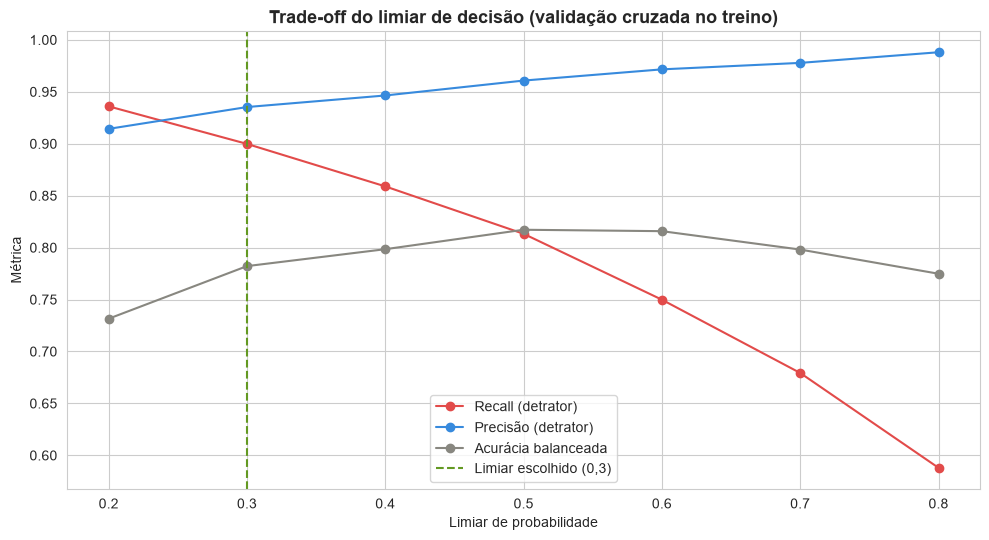

In [15]:
plt.figure(figsize=(10, 5.5))
plt.plot(tabela_limiar['limiar'], tabela_limiar['recall'], marker='o',
         color='#E24B4A', label='Recall (detrator)')
plt.plot(tabela_limiar['limiar'], tabela_limiar['precisao'], marker='o',
         color='#378ADD', label='Precisão (detrator)')
plt.plot(tabela_limiar['limiar'], tabela_limiar['acuracia_balanceada'], marker='o',
         color='#888780', label='Acurácia balanceada')
plt.axvline(0.3, color='#639922', linestyle='--', label='Limiar escolhido (0,3)')
plt.title('Trade-off do limiar de decisão (validação cruzada no treino)',
          fontsize=13, fontweight='bold')
plt.xlabel('Limiar de probabilidade')
plt.ylabel('Métrica')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/figures/16_tradeoff_limiar.png', dpi=120, bbox_inches='tight')
plt.show()

**Recall e precisão se movem em direções opostas, sempre.** Baixar o limiar marca mais clientes como detratores: captura mais detratores reais e também mais alarmes falsos. Subir o limiar faz o contrário. Em 0,8 a precisão chega a 98,8%, mas 41% dos detratores passam despercebidos.

**Limiar escolhido: 0,3.** O recall sobe de 0,813 (no limiar padrão) para 0,900, capturando 9 em cada 10 detratores, enquanto a precisão cai apenas de 0,961 para 0,935.

A justificativa é o custo assimétrico dos dois erros. Deixar de identificar um cliente insatisfeito significa perder a chance de reverter, e a análise exploratória mostrou que nenhum detrator recompra em 30 dias. Já contatar um cliente que avaliaria bem tem custo baixo e pode até fortalecer o relacionamento. Duas ressalvas acompanham a decisão: contato em excesso incomoda, e a capacidade de atendimento é finita, por isso o limiar não foi reduzido ainda mais (em 0,2 a acurácia balanceada cairia de 0,782 para 0,732, um custo alto por um ganho pequeno de recall).

Na prática, o modelo é entregue como um **score de risco**, e o limiar pode ser ajustado conforme a capacidade de contato do time.

## 12. Modelo final e exportação

Com a avaliação concluída e as métricas oficiais registradas, o modelo é retreinado com a base completa: mais dados produzem um modelo um pouco melhor, e o conjunto de teste já cumpriu seu papel.

Duas saídas são geradas:

- `models/modelo_detrator.joblib`: o pipeline completo (pré-processamento e modelo), pronto para ser carregado e aplicado a novos pedidos sem retreinar
- `data/processed/nps_com_score.csv`: a base com a probabilidade de detração e a faixa de risco de cada pedido, que alimenta o dashboard construído na etapa seguinte do projeto

**Ressalva:** como o modelo final viu todas as linhas, as probabilidades deste arquivo são otimistas e servem para visualização e priorização, não para medir desempenho. O desempenho oficial é o do conjunto de teste, na seção 7.

As faixas de risco usam o limiar escolhido como primeira fronteira: **Baixo** abaixo de 0,3, **Médio** entre 0,3 e 0,7, **Alto** acima de 0,7.

In [16]:
pipe.fit(X, y)

joblib.dump(pipe, '../models/modelo_detrator.joblib')

['../models/modelo_detrator.joblib']

In [17]:
scored = df.copy()

scored["prob_detrator"] = pipe.predict_proba(X)[:, 1].round(4)

scored["faixa_risco"] = pd.cut(
    scored["prob_detrator"],
    bins=[-0.1, 0.3, 0.7, 1.0],
    labels=["Baixo", "Médio", "Alto"]
)

scored.to_csv("../data/processed/nps_com_score.csv", index=False)

scored.groupby("faixa_risco", observed=True).agg(
    pedidos=("order_id", "count"),
    taxa_detratores=("isdetrator", "mean"),
    nps_medio=("nps_score", "mean"),
    atraso_medio=("delivery_delay_days", "mean"),
).round(3)

,pedidos,taxa_detratores,nps_medio,atraso_medio
faixa_risco,,,,
Baixo,472,0.451,7.162,0.676
Médio,594,0.820,5.318,1.571
Alto,1434,0.983,3.073,2.940


As faixas separam bem os grupos: na faixa Alto praticamente todos são detratores (98,3%) e o atraso médio passa de 3 dias; na faixa Baixo a taxa cai para 45,1% e o atraso médio fica abaixo de 1 dia.

Atenção à leitura da faixa "Baixo": numa base em que 84% são detratores, risco baixo é **relativo**. Não significa cliente satisfeito, significa chance de detração bem abaixo da média.

## 13. Conclusões e limitações

**É possível antecipar a detração com dados operacionais.** A Regressão Logística atinge ROC-AUC de 0,870 no conjunto de teste, contra 0,500 do classificador trivial, sem usar nenhuma informação vinda da resposta do cliente.

**O atraso em relação ao prazo prometido é o principal motor da detração**, seguido pelo número de reclamações e pelo tempo de resolução. O modelo confirma, por outra técnica, o achado central da análise exploratória, e reforça a recomendação de recalibrar o prazo prometido.

**A acurácia enganaria a leitura.** O chute trivial tem 84% de acurácia, por isso a avaliação se apoiou em ROC-AUC, acurácia balanceada e F1 macro.

**O CSAT interno foi excluído sem perda de desempenho**, eliminando um risco de vazamento ao custo de nada.

### Limitações

- A base é **sintética**, fornecida como desafio acadêmico. As relações tendem a ser mais limpas que em dados reais, e os resultados não devem ser lidos como expectativa de produção
- A premissa de que reclamações, contatos e resolução ocorrem antes da pesquisa de NPS **não pode ser verificada**, porque a base não tem datas. Em um cenário real, essa validação seria o primeiro passo antes de levar o modelo adiante
- Sem dimensão temporal, não foi possível validar o modelo em um período futuro (validação out-of-time), que é o teste mais próximo do uso real
- Os coeficientes indicam associação, não causalidade
- Variáveis correlacionadas entre si (reclamações e contatos) dividem o peso, então os coeficientes individuais devem ser lidos com cautela

### Próximos passos

- Dashboard em Power BI sobre `nps_com_score.csv`, com a lista priorizada por risco e o acompanhamento dos fatores operacionais